# Start here: a new research topic in an afternoon

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melhzy/pubmed-stream/blob/main/tutorials/00_new_topic.ipynb) Run it in your browser with nothing to install, or on your own computer: [how to run the tutorials](guides/setup.md).

You have a new question and an afternoon. This notebook takes you from the question to a map of its literature, the way an experienced reviewer would, but in minutes:

1. **Frame the question** as a few concepts.
2. **Size the literature**: how much is there, and which searches are precise.
3. **Collect** the core papers.
4. **Find the paper everyone cites**, the field's landmark.
5. **Build a knowledge graph** that links papers by citation and topic.
6. **Read the graph**: growth, themes, kinds of evidence, what to read first, and gaps.
7. **Export a reading list** for Zotero or EndNote.
8. **Open it in Obsidian** and start writing.

The example question is about the **gut microbiome in Parkinson's disease**. To study your own question, change only the **Your settings** cell.

**New to notebooks?** A notebook is a document with runnable boxes, called *cells*. Grey cells hold code; you never need to read it. Run the whole notebook with **Run > Run All Cells** in Jupyter, or **Runtime > Run all** in Colab, and the results appear under each cell. Words such as MeSH, PMC or stub are explained in the [glossary](guides/glossary.md). The notebook takes about five minutes.

## Your settings

This is the only cell you need to edit. Change the values, keeping text between the quotes, then run the whole notebook.

In [1]:
QUESTION = "How does the gut microbiome relate to Parkinson's disease, and can fecal microbiota transplantation help?"
TOPIC = "gut microbiome parkinson"   # a short name; the knowledge graph is saved as kg_<topic>

# The question's main ideas. For each: the words authors use, and its MeSH heading,
# which you can look up at https://www.ncbi.nlm.nih.gov/mesh
CONCEPTS = {
    "Gut microbiome": {"words": ["gut microbiota", "gut microbiome"], "mesh": "gastrointestinal microbiome"},
    "Parkinson's disease": {"words": ["parkinson"], "mesh": "parkinson disease"},
    "Fecal transplant": {"words": ["fecal microbiota transplantation"], "mesh": "fecal microbiota transplantation"},
}
CORE = ["Gut microbiome", "Parkinson's disease"]   # concepts every paper in the study must be about

PAPERS_PER_SEARCH = 30   # full-text papers to download per search
SEED = ""                # PubMed ID of a key paper; leave empty to use the paper your corpus cites most
NEIGHBORS = 30           # similar, citing and cited papers to add around the key paper
NCBI_API_KEY = ""   # optional: paste your free NCBI key between the quotes to run about three times faster

In [2]:
# Setup: run this cell as it is. In Google Colab it first fetches the tutorial files.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/pubmed-stream"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/melhzy/pubmed-stream.git", "/content/pubmed-stream"], check=True)
    sys.path.insert(0, "/content/pubmed-stream/tutorials")

import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import tutorial_utils as tu

tu.setup("new_topic", api_key=NCBI_API_KEY)
tu.style()

from pubmed_stream import RateLimiter, create_kg, create_session, esearch_pmc, search_and_download

API_KEY = os.environ.get("NCBI_API_KEY")
session = create_session("pubmed-stream-tutorial")
limiter = RateLimiter(0.1 if API_KEY else 0.34)

## 1. Frame the question

A search engine cannot read a question, so break it into its main **concepts**. For each concept, list the words authors use, and find its **MeSH heading**: the standard term PubMed's indexers attach to every article about it, whatever words the authors chose. Some concepts are the **core** that every paper must be about; others, like a treatment, are what you want to learn about inside that core.

In [3]:
def words_query(name, field="Title/Abstract"):
    """Any of the concept's words in the given field."""
    return "(" + " OR ".join(f'"{w}"[{field}]' for w in CONCEPTS[name]["words"]) + ")"

def mesh_query(name):
    return f'"{CONCEPTS[name]["mesh"]}"[mh]'

print("Question:", QUESTION, "\n")
pd.DataFrame([
    {"concept": name, "core": name in CORE, "author words": ", ".join(c["words"]), "MeSH heading": c["mesh"],
     "search": f"{words_query(name)} OR {mesh_query(name)}"}
    for name, c in CONCEPTS.items()
])

Question: How does the gut microbiome relate to Parkinson's disease, and can fecal microbiota transplantation help? 



,concept,core,author words,MeSH heading,search
0,Gut microbiome,True,"gut microbiota, gut microbiome",gastrointestinal microbiome,"(""gut microbiota""[Title/Abstract] OR ""gut micr..."
1,Parkinson's disease,True,parkinson,parkinson disease,"(""parkinson""[Title/Abstract]) OR ""parkinson di..."
2,Fecal transplant,False,fecal microbiota transplantation,fecal microbiota transplantation,"(""fecal microbiota transplantation""[Title/Abst..."


## 2. How much literature is there?

Before downloading anything, count. Each line below is a search, from broad to narrow. Each concept alone returns tens of thousands of articles; combining the core concepts, and asking for them in the **title**, narrows it to papers that are really about the question. A first map works best with a few hundred papers.

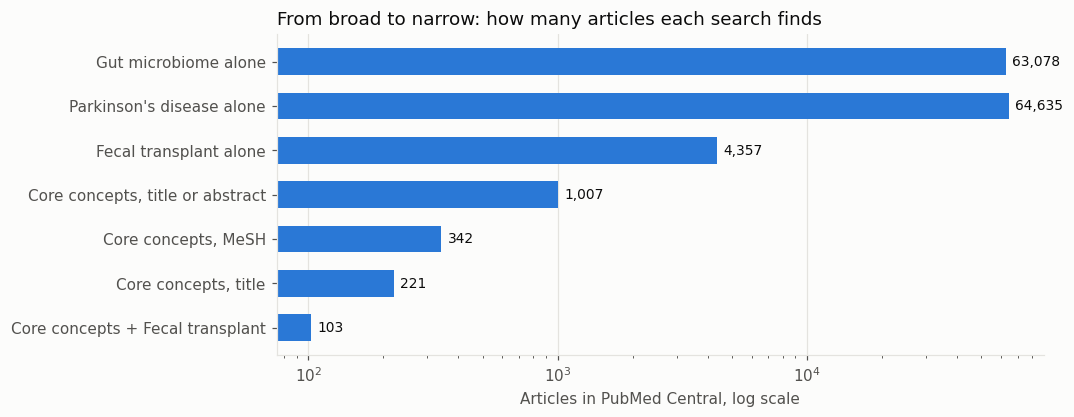

In [4]:
def count(query):
    return esearch_pmc(query, 0, API_KEY, session, limiter)[1]

core_words = " AND ".join(words_query(n) for n in CORE)
core_title = " AND ".join(words_query(n, "Title") for n in CORE)
core_mesh = " AND ".join(mesh_query(n) for n in CORE)
extra = [n for n in CONCEPTS if n not in CORE]

searches = {f"{n} alone": words_query(n) for n in CONCEPTS}
searches["Core concepts, title or abstract"] = core_words
searches["Core concepts, MeSH"] = core_mesh
searches["Core concepts, title"] = core_title
for n in extra:
    searches[f"Core concepts + {n}"] = f"{core_words} AND ({words_query(n)} OR {mesh_query(n)})"

sizes = pd.Series({label: count(q) for label, q in searches.items()})

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(sizes.index[::-1], sizes.values[::-1], color=tu.BLUE, height=0.6)
ax.set_xscale("log")
tu.bar_labels(ax, bars, fmt="{:,.0f}", horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Articles in PubMed Central, log scale")
ax.set_title("From broad to narrow: how many articles each search finds")
plt.show()

The study uses two complementary searches for the core: words in the **title** catch the newest papers, and **MeSH** headings catch indexed papers that use other words. Tutorial 2 measures why both are needed.

## 3. Collect the core papers

Each search downloads the newest full-text papers that are free to reuse. Running it again later only fetches what is new.

In [5]:
QUERIES = [core_title, core_mesh]
with tu.quiet():   # hide the download progress
    downloads = [search_and_download(q, max_results=PAPERS_PER_SEARCH) for q in QUERIES]

pd.DataFrame([{"search": tu.short(q, 70), "found": s.total_found, "downloaded": s.successful + s.skipped,
               "not downloadable": s.unavailable} for q, s in zip(QUERIES, downloads)])

,search,found,downloaded,not downloadable
0,"(""gut microbiota""[Title] OR ""gut microbiome""[T...",221,30,0
1,"""gastrointestinal microbiome""[mh] AND ""parkins...",342,29,1


*Not downloadable* papers are in PMC, but their publishers do not allow the full text to be reused. They can still join the knowledge graph through the key paper's neighborhood, in step 5.

## 4. Find the paper everyone cites

Every downloaded paper lists its references. The works cited by many of your papers are the field's foundations, usually a landmark review or the original discovery. Reading one of them first gives you the field's vocabulary, and the knowledge graph uses it as the **key paper**: its similar, citing and cited papers join the study.

In [6]:
articles = {}
for stats in downloads:
    for path in stats.output_dir.glob("PMC*.json"):
        article = json.loads(path.read_text(encoding="utf-8"))
        articles[article["pmcid"]] = article

cited, details = Counter(), {}
for article in articles.values():
    for pmid in {r["pmid"] for r in article["metadata"].get("references", []) if r.get("pmid")}:
        cited[pmid] += 1
for article in articles.values():
    for r in article["metadata"].get("references", []):
        if r.get("pmid") in cited:
            details.setdefault(r["pmid"], (r.get("title") or "", r.get("year") or ""))

foundations = pd.DataFrame([
    {"PubMed ID": pmid, "cited by": f"{n} of {len(articles)} papers", "year": details[pmid][1],
     "title": tu.short(details[pmid][0], 90)}
    for pmid, n in cited.most_common(8)
])
key_paper = SEED or foundations["PubMed ID"].iloc[0]
print(f"{len(articles)} papers. Key paper: PMID {key_paper}\n")
foundations

51 papers. Key paper: PMID 27912057



,PubMed ID,cited by,year,title
0,27912057,21 of 51 papers,2016,Gut microbiota regulate motor deficits and neu...
1,28195358,13 of 51 papers,2017,Parkinson’s disease and Parkinson’s disease me...
2,33692356,13 of 51 papers,2021,Meta-analysis of the Parkinson’s disease gut m...
3,35750883,12 of 51 papers,2022,The microbiome-gut-brain axis in Parkinson dis...
4,36376318,12 of 51 papers,2022,Metagenomics of Parkinson’s disease implicates...
5,33557896,12 of 51 papers,2021,"Relationships of gut microbiota, short-chain f..."
6,34784980,10 of 51 papers,2021,Fecal microbiota transplantation protects rote...
7,25476529,10 of 51 papers,2015,Gut microbiota are related to Parkinson's dise...


## 5. Build the knowledge graph

One call turns the searches and the key paper into an [Obsidian](https://obsidian.md) vault: one note per paper, per MeSH concept and per search, all linked. Papers from the key paper's neighborhood that were not downloaded become **stubs**: notes with their PubMed details and links but no full text.

In [7]:
with tu.quiet():
    result = create_kg(TOPIC, queries=QUERIES, seeds=[key_paper], max_results=PAPERS_PER_SEARCH,
                       max_per_relation=NEIGHBORS)
print(result)

kg = tu.read_kg(result.kg_dir)
papers = kg["papers"]
in_graph_citations = Counter(t for p in papers.values() for t in p["cites"] if t in papers)


Knowledge graph: gut microbiome parkinson
Folder:            workspace\new_topic\kg_gut_microbiome_parkinson
Study searches:    2 (2 run now, 0 new articles)
Study seeds:       1 (1 fetched now)
Obsidian vault
Vault:             workspace\new_topic\kg_gut_microbiome_parkinson
Sources:           3
Papers:            141 (51 full text, 90 stubs)
MeSH concepts:     315
Collections:       3
Notes:             460 created, 0 updated, 0 unchanged
PubMed records:    70 fetched
  - Without MeSH:  34 (offline, or not yet indexed in PubMed)


## 6. Read the graph

The rest of this notebook asks the graph the questions a researcher asks of a new field.

### How fast is the field growing?

PMC's yearly counts for the core concepts, in titles or abstracts, show whether the field is new, booming or mature. The current year is not over, so it is left out.

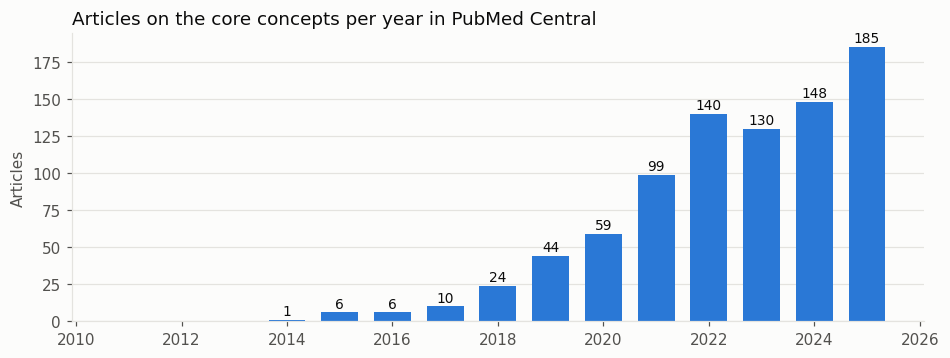

In [8]:
import datetime

last_year = datetime.date.today().year - 1
growth = pd.Series({year: count(f"{core_words} AND {year}[pdat]") for year in range(last_year - 14, last_year + 1)})

fig, ax = plt.subplots(figsize=(10, 3.4))
bars = ax.bar(growth.index, growth.values, color=tu.BLUE, width=0.7)
tu.bar_labels(ax, bars, fmt="{:,.0f}")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
tu.gridlines(ax)
ax.set_ylabel("Articles")
ax.set_title("Articles on the core concepts per year in PubMed Central")
plt.show()

### What are the main themes?

A MeSH heading marked as a **major topic** is a main point of the paper. Counting major topics across the graph, without the core concepts themselves, shows what the field studies.

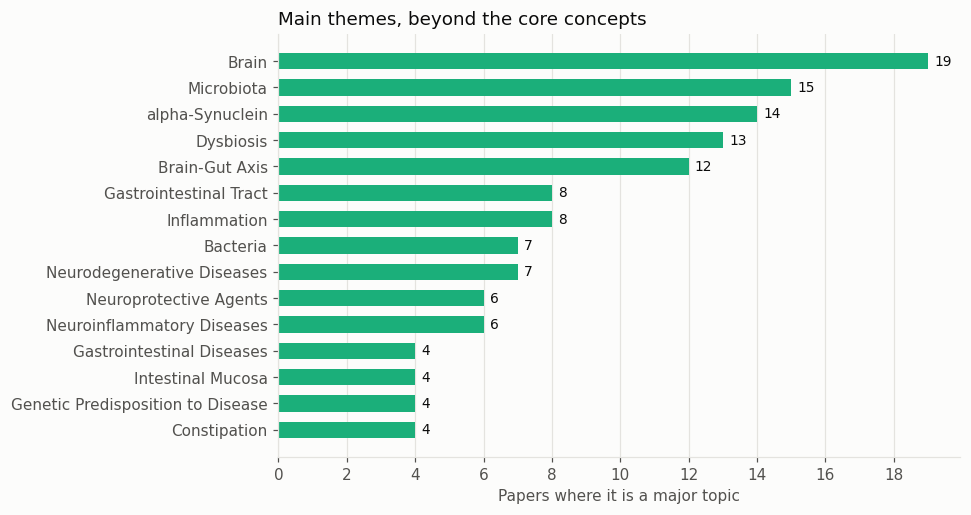

In [9]:
core_headings = {CONCEPTS[n]["mesh"].casefold() for n in CORE}
themes = Counter(name for name, members in kg["concepts"].items() if name.casefold() not in core_headings
                 for major in members.values() if major).most_common(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh([n for n, _ in themes], [c for _, c in themes], color=tu.AQUA, height=0.62)
tu.bar_labels(ax, bars, horizontal=True)
tu.gridlines(ax, "x")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Papers where it is a major topic")
ax.set_title("Main themes, beyond the core concepts")
plt.show()

### What kind of evidence is there?

Publication types and MeSH headings tell a review from a trial, and a mouse study from a human one. The newest papers are not indexed yet, so they appear as *not indexed yet* until PubMed catches up.

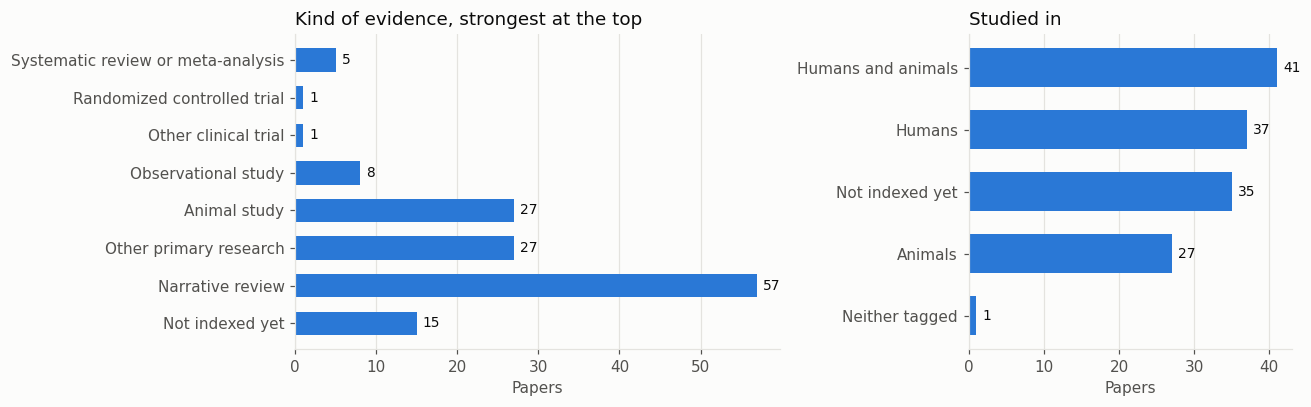

In [10]:
TRIALS = ("Clinical Trial", "Randomized Controlled Trial")
OBSERVATIONAL = {"Cohort Studies", "Case-Control Studies", "Cross-Sectional Studies", "Prospective Studies",
                 "Retrospective Studies", "Longitudinal Studies"}

def evidence(p):
    types, mesh = set(p["publication_types"]), set(p["mesh"])
    if types & {"Meta-Analysis", "Systematic Review"}:
        return "Systematic review or meta-analysis"
    if "Randomized Controlled Trial" in types:
        return "Randomized controlled trial"
    if any(t.startswith("Clinical Trial") for t in types):
        return "Other clinical trial"
    if mesh & OBSERVATIONAL:
        return "Observational study"
    if "Review" in types:
        return "Narrative review"
    if "Animals" in mesh and "Humans" not in mesh:
        return "Animal study"
    return "Other primary research" if mesh else "Not indexed yet"

def subjects(p):
    mesh = set(p["mesh"])
    if not mesh:
        return "Not indexed yet"
    return {(True, True): "Humans and animals", (True, False): "Humans", (False, True): "Animals"}.get(
        ("Humans" in mesh, "Animals" in mesh), "Neither tagged")

EVIDENCE_ORDER = ["Systematic review or meta-analysis", "Randomized controlled trial", "Other clinical trial",
                  "Observational study", "Animal study", "Other primary research", "Narrative review", "Not indexed yet"]
kinds = pd.Series([evidence(p) for p in papers.values()]).value_counts().reindex(EVIDENCE_ORDER, fill_value=0)
who = pd.Series([subjects(p) for p in papers.values()]).value_counts()

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
bars = left.barh(kinds.index[::-1], kinds.values[::-1], color=tu.BLUE, height=0.62)
tu.bar_labels(left, bars, horizontal=True, zero=True)
tu.gridlines(left, "x")
left.set_xlabel("Papers")
left.set_title("Kind of evidence, strongest at the top")
bars = right.barh(who.index[::-1], who.values[::-1], color=tu.BLUE, height=0.62)
tu.bar_labels(right, bars, horizontal=True)
tu.gridlines(right, "x")
right.set_xlabel("Papers")
right.set_title("Studied in")
plt.tight_layout()
plt.show()

### What should I read first?

A short list, each for a reason: the reviews the study relies on most, the primary studies it relies on most, and the newest papers. Citations are counted **inside the graph**, which measures how much this literature builds on a paper.

In [11]:
def row(key, why):
    p = papers[key]
    return {"why": why, "year": p["year"], "title": tu.short(p["title"], 80),
            "cited in graph": in_graph_citations[key], "PubMed ID": p["pmid"]}

reviews = [k for k, _ in in_graph_citations.most_common() if "Review" in papers[k]["publication_types"]][:3]
primary = [k for k, _ in in_graph_citations.most_common()
           if evidence(papers[k]) not in ("Narrative review", "Systematic review or meta-analysis")][:3]
newest = sorted((k for k in papers if papers[k]["status"] == "full-text"), key=lambda k: papers[k]["year"] or 0)[-3:][::-1]

reading_list = pd.DataFrame([row(k, "Most relied-on review") for k in reviews]
                            + [row(k, "Most relied-on study") for k in primary]
                            + [row(k, "Newest") for k in newest])
reading_list

,why,year,title,cited in graph,PubMed ID
0,Most relied-on review,2021,The role of gut dysbiosis in Parkinson's disea...,8,33856024
1,Most relied-on review,2024,"Gut microbiome, short-chain fatty acids, alpha...",5,38377788
2,Most relied-on review,2020,Chronic stress-induced gut dysfunction exacerb...,4,30579705
3,Most relied-on study,2016,Gut Microbiota Regulate Motor Deficits and Neu...,50,27912057
4,Most relied-on study,2016,Short chain fatty acids and gut microbiota dif...,11,27591074
5,Most relied-on study,2015,Gut microbiota are related to Parkinson's dise...,11,25476529
6,Newest,2026,Beyond bacteria: a multi-omics view of the gut...,0,42798356
7,Newest,2026,The gut microbiota-short-chain fatty acid-infl...,0,42787718
8,Newest,2026,Blood-Mediated Gut–Brain Axis in Parkinson’s D...,0,42782818


### Is anything retracted?

Retracted papers can still be cited for years. The graph marks them, and Obsidian colours them red.

In [12]:
retracted = [p for p in papers.values() if p["retracted"]]
print(f"Retracted papers in the graph: {len(retracted)}")
for p in retracted:
    print(f"  PMID {p['pmid']} ({p['year']}): {tu.short(p['title'], 90)}")

Retracted papers in the graph: 0


### Where are the gaps?

For each concept outside the core, how many papers in the graph address it, and how many of those are human trials? Few papers, or none in humans, marks an open question, and possibly your next study.

In [13]:
def addresses(p, name):
    c = CONCEPTS[name]
    return (c["mesh"].casefold() in {m.casefold() for m in p["mesh"]}
            or any(w.casefold() in p["title"].casefold() for w in c["words"]))

gaps = pd.DataFrame([
    {"concept": name,
     "papers": sum(addresses(p, name) for p in papers.values()),
     "in humans": sum(addresses(p, name) and "Humans" in p["mesh"] for p in papers.values()),
     "clinical trials": sum(addresses(p, name) and evidence(p).endswith(("controlled trial", "clinical trial"))
                            for p in papers.values())}
    for name in extra
])
gaps

,concept,papers,in humans,clinical trials
0,Fecal transplant,8,4,1


## 7. Export a reading list for Zotero or EndNote

`reading_list.ris` holds every paper in the graph. In Zotero choose **File > Import**, in EndNote **File > Import > File** with the *Reference Manager (RIS)* filter. `reading_list.csv` opens in Excel.

In [14]:
def ris(p):
    lines = ["TY  - JOUR", f"TI  - {p['title']}"]
    lines += [f"AU  - {a}" for a in p["authors"]]
    for tag, value in (("PY", p["year"]), ("JO", p["journal"]), ("DO", p["doi"]), ("UR", p["url"]), ("AN", p["pmid"])):
        if value:
            lines.append(f"{tag}  - {value}")
    return "\n".join(lines + ["ER  - "])

ordered = sorted(papers.values(), key=lambda p: -in_graph_citations[p["key"]])
Path("reading_list.ris").write_text("\n\n".join(ris(p) for p in ordered) + "\n", encoding="utf-8")
pd.DataFrame([{"pmid": p["pmid"], "doi": p["doi"], "year": p["year"], "journal": p["journal"], "title": p["title"],
               "evidence": evidence(p), "cited_in_graph": in_graph_citations[p["key"]], "full_text": p["status"] == "full-text"}
              for p in ordered]).to_csv("reading_list.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: Excel shows accents correctly
print(f"Wrote reading_list.ris and reading_list.csv with {len(ordered)} papers. The first entry:\n")
print(ris(ordered[0]))

Wrote reading_list.ris and reading_list.csv with 141 papers. The first entry:

TY  - JOUR
TI  - Gut Microbiota Regulate Motor Deficits and Neuroinflammation in a Model of Parkinson's Disease.
AU  - Sampson Timothy R
AU  - Debelius Justine W
AU  - Thron Taren
AU  - Janssen Stefan
AU  - Shastri Gauri G
AU  - Ilhan Zehra Esra
AU  - Challis Collin
AU  - Schretter Catherine E
AU  - Rocha Sandra
AU  - Gradinaru Viviana
AU  - Chesselet Marie-Francoise
AU  - Keshavarzian Ali
AU  - Shannon Kathleen M
AU  - Krajmalnik-Brown Rosa
AU  - Wittung-Stafshede Pernilla
AU  - Knight Rob
AU  - Mazmanian Sarkis K
PY  - 2016
JO  - Cell
DO  - 10.1016/j.cell.2016.11.018
UR  - https://pubmed.ncbi.nlm.nih.gov/27912057/
AN  - 27912057
ER  - 


## 8. Open it in Obsidian and start writing

The knowledge graph is a folder of notes. On your own computer, open it in [Obsidian](https://obsidian.md) with **Open folder as vault**. In Colab, the next cell first saves it to your computer as a zip file. The [Obsidian guide](guides/obsidian.md) shows how to find your way around it.

In [15]:
if tu.in_colab():
    tu.download(result.kg_dir)
    tu.download("reading_list.ris")
else:
    print(f"Open this folder in Obsidian: tutorials/workspace/new_topic/{result.kg_dir.name}")

Open this folder in Obsidian: tutorials/workspace/new_topic/kg_gut_microbiome_parkinson


## The rest of your afternoon

| Time | Do this |
|---|---|
| 15 min | Run this notebook with your own question, and check the search sizes in step 2. |
| 45 min | Read the key paper from step 4 and the reviews in the reading list. |
| 60 min | In Obsidian, open the graph view, follow the main themes' concept notes, and write your own notes under each paper. |
| 15 min | Note the gaps from step 6 as candidate questions. |

Next week, run the notebook again: the searches fetch only new papers, and the graph adds them while keeping your notes. Before you rely on the results, read [what pubmed-stream can and cannot do](guides/limitations.md).

**Learn more:** tutorial 2 for precise searches, tutorial 4 for the evidence around one paper, and tutorial 5 for everything in a knowledge graph.